In [1]:
import pandas as pd
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, f1_score, precision_score, classification_report, confusion_matrix
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA


In [2]:
df = pd.read_csv("Bangladesh_Crime_Dataset_A.csv")
df.head(5)

,Unnamed: 0,incident_month,incident_week,incident_weekday,weekend,part_of_the_day,incident_district,incident_division,precip,visibility,...,average_household_size,density_per_kmsq,literacy_rate,religious_institution,playground,park,police_station,school,college,crime
0,0,7.0,29,wednesday,0,morning,dhaka,dhaka,6.1,10,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
1,1,1.0,2,wednesday,0,night,dhaka,dhaka,0.0,10,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
2,2,1.0,4,tuesday,0,night,dhaka,dhaka,0.0,10,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
3,3,3.0,9,friday,1,night,dhaka,dhaka,0.0,10,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
4,4,8.0,34,thursday,0,night,dhaka,dhaka,21.9,9,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder


In [3]:
df.columns

Index(['Unnamed: 0', 'incident_month', 'incident_week', 'incident_weekday',
       'weekend', 'part_of_the_day', 'incident_district', 'incident_division',
       'precip', 'visibility', 'heatindex', 'season', 'male_population',
       'female_population', 'total_population', 'gender_ration',
       'average_household_size', 'density_per_kmsq', 'literacy_rate',
       'religious_institution', 'playground', 'park', 'police_station',
       'school', 'college', 'crime'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6574 entries, 0 to 6573
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              6574 non-null   int64  
 1   incident_month          5917 non-null   float64
 2   incident_week           6574 non-null   int64  
 3   incident_weekday        6574 non-null   object 
 4   weekend                 6574 non-null   int64  
 5   part_of_the_day         6457 non-null   object 
 6   incident_district       6246 non-null   object 
 7   incident_division       6574 non-null   object 
 8   precip                  6574 non-null   float64
 9   visibility              6574 non-null   int64  
 10  heatindex               6574 non-null   int64  
 11  season                  6574 non-null   object 
 12  male_population         6574 non-null   int64  
 13  female_population       6574 non-null   int64  
 14  total_population        6574 non-null   

In [5]:
df.isnull().sum()

Unnamed: 0                  0
incident_month            657
incident_week               0
incident_weekday            0
weekend                     0
part_of_the_day           117
incident_district         328
incident_division           0
precip                      0
visibility                  0
heatindex                   0
season                      0
male_population             0
female_population           0
total_population            0
gender_ration               0
average_household_size      0
density_per_kmsq            0
literacy_rate             328
religious_institution       0
playground                  0
park                        0
police_station              0
school                      0
college                     0
crime                       0
dtype: int64

In [6]:
df['incident_month'].value_counts

<bound method IndexOpsMixin.value_counts of 0        7.0
1        1.0
2        1.0
3        3.0
4        8.0
        ... 
6569     3.0
6570    10.0
6571     NaN
6572     1.0
6573     1.0
Name: incident_month, Length: 6574, dtype: float64>

In [7]:
df['part_of_the_day'].value_counts

<bound method IndexOpsMixin.value_counts of 0       morning
1         night
2         night
3         night
4         night
         ...   
6569      night
6570      night
6571      night
6572      night
6573      night
Name: part_of_the_day, Length: 6574, dtype: object>

In [8]:
df['incident_district'].value_counts

<bound method IndexOpsMixin.value_counts of 0            dhaka
1            dhaka
2            dhaka
3            dhaka
4            dhaka
           ...    
6569    munshiganj
6570    munshiganj
6571    munshiganj
6572        sylhet
6573      pirojpur
Name: incident_district, Length: 6574, dtype: object>

In [9]:
df['literacy_rate'].value_counts

<bound method IndexOpsMixin.value_counts of 0       74.6
1       74.6
2       74.6
3       74.6
4       74.6
        ... 
6569    57.1
6570    57.1
6571    57.1
6572    49.4
6573    61.2
Name: literacy_rate, Length: 6574, dtype: float64>

In [10]:
kolom_teks = ['incident_division', 'season', 'incident_weekday', 'part_of_the_day']

for col in kolom_teks:
    print(f"\n[Isi Unik Kolom: {col.upper()}]")
    nilai_unik = df[col].unique()
    print(nilai_unik)
    
    print(f"-> Total Variasi: {len(nilai_unik)}")
    if len(nilai_unik) > 10: 
        print("")
    


[Isi Unik Kolom: INCIDENT_DIVISION]
['dhaka' 'DHAKA' 'Dhaka' '  dhaka ' 'dhaKA' 'DhaKA' 'DhAka' 'DHAkA'
 'dHaKA' 'gazipur' 'dhaKa' 'dHaKa' 'DhaKa' 'dhAka' 'dHAkA' 'DHAKa' 'dHakA'
 'dhAKa' 'DhakA' 'GazIPur' 'dHAKA' 'dHaka' 'chattogram' 'CHAtTogRam'
 'CHATtOGrAm' 'CHATTOGRAM' 'chATToGraM' '  chattogram ' 'Chattogram'
 'CHaTtogRAm' 'chaTTOGrAM' 'ChaTtOGram' 'cHAtTOGram' 'ChatTogRAM'
 'ChAtTOGram' 'CHAttOgRAM' 'cHATTOgram' 'cHAtToGram' 'cHATToGrAM'
 'cHaTtOgRaM' 'chATTOgram' 'CHAtToGRam' 'cHaTtoGRAM' 'ChAttoGram'
 'rajshahi' 'khulna' 'KHULNA' 'Rajshahi' 'KHuLNA' '  khulna ' 'Khulna'
 'KhULnA' 'barisAl' 'barisal' 'sYLHEt' '  rajshahi ' 'sylhet' 'rangpur'
 'kHULNa' 'khULnA' 'SYLHET' '  sylhet ' 'KhUlNa' 'RAJSHAHI' 'mymensingh'
 'Barisal' 'RANGPUR' 'BARISAL' 'bArisAl' '  rangpur ' 'RaJshAhi'
 'RaJShahi' 'Rangpur' 'Mymensingh' 'MYMenSIngh' 'KhULna' 'KhuLna' 'KHuLnA'
 'mYMENsIngh' 'Sylhet' 'chattOgRAm' 'barIsal' 'mYmENSIngh' 'myMEnSiNgH'
 '  mymensingh ' 'MYMENSINGH' '  barisal ' 'DHaKA' 'cHat

In [11]:
# Cek kolom 'incident_division' (Sering beda huruf besar/kecil)
divisi_unik = df['incident_division'].unique()
print(f"-> Anomali di 'incident_division' (Contoh 10 teratas):\n   {divisi_unik[:10]}")
# Nanti bakal kelihatan: 'dhaka', 'DHAKA', '  dhaka '

# Cek kolom 'season'
print(f"-> Unik di 'season': {df['season'].unique()}")

# Cek kolom 'part_of_the_day'
print(f"-> Unik di 'part_of_the_day': {df['part_of_the_day'].unique()}")

-> Anomali di 'incident_division' (Contoh 10 teratas):
   ['dhaka' 'DHAKA' 'Dhaka' '  dhaka ' 'dhaKA' 'DhaKA' 'DhAka' 'DHAkA'
 'dHaKA' 'gazipur']
-> Unik di 'season': ['rainy' 'winter' 'hot']
-> Unik di 'part_of_the_day': ['morning' 'night' 'evening' 'noon' nan 'afternoon']


In [12]:

cols_to_check = ['police_station', 'density_per_kmsq', 'total_population']

print("\nStatistik Sederhana :")
pd.options.display.float_format = '{:.2f}'.format 
print(df[cols_to_check].describe().loc[['min', 'max']])

# 'police_station'  Kalau Min-nya -1, itu anomali
# 'density_per_kmsq' Kalau Max-nya angka raksasa, itu ANOMALI.


Statistik Sederhana :
     police_station                                   density_per_kmsq  \
min           -1.00                                               0.00   
max           74.00 10903148741055864941166842455320750318700532165...   

     total_population  
min          22871.00  
max        8906039.00  


In [13]:
cols_text = ['incident_division', 'incident_district', 'season', 'part_of_the_day', 'incident_weekday']
for col in cols_text:
    df[col] = df[col].astype(str).str.lower().str.strip()
    df[col] = df[col].replace('nan', np.nan) 

# benerin Kantor Polisi Minus (-1)
df.loc[df['police_station'] < 0, 'police_station'] = np.nan

# kepadatan penduduk
df.loc[df['density_per_kmsq'] > 100000, 'density_per_kmsq'] = np.nan

In [14]:
#cek iseng
kolom_teks = ['incident_division', 'season', 'incident_weekday', 'part_of_the_day']

for col in kolom_teks:
    print(f"\n[Isi Unik Kolom: {col.upper()}]")
    nilai_unik = df[col].unique()
    print(nilai_unik)
    
    print(f"-> Total Variasi: {len(nilai_unik)}")
    if len(nilai_unik) > 10: 
        print("")
    


[Isi Unik Kolom: INCIDENT_DIVISION]
['dhaka' 'gazipur' 'chattogram' 'rajshahi' 'khulna' 'barisal' 'sylhet'
 'rangpur' 'mymensingh']
-> Total Variasi: 9

[Isi Unik Kolom: SEASON]
['rainy' 'winter' 'hot']
-> Total Variasi: 3

[Isi Unik Kolom: INCIDENT_WEEKDAY]
['wednesday' 'tuesday' 'friday' 'thursday' 'sunday' 'saturday' 'monday']
-> Total Variasi: 7

[Isi Unik Kolom: PART_OF_THE_DAY]
['morning' 'night' 'evening' 'noon' nan 'afternoon']
-> Total Variasi: 6


In [15]:
#missing value
df.isnull().sum()

Unnamed: 0                  0
incident_month            657
incident_week               0
incident_weekday            0
weekend                     0
part_of_the_day           117
incident_district         328
incident_division           0
precip                      0
visibility                  0
heatindex                   0
season                      0
male_population             0
female_population           0
total_population            0
gender_ration               0
average_household_size      0
density_per_kmsq           60
literacy_rate             328
religious_institution       0
playground                  0
park                        0
police_station              1
school                      0
college                     0
crime                       0
dtype: int64

In [16]:
#handling
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())


cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    if len(df[col].mode()) > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

In [17]:
#hanling outlier
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
outlier_summary = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR


    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_summary[col] = len(outliers)

print("Jumlah outlier per fitur (IQR):\n")
for k, v in outlier_summary.items():
    if v > 0: 
        print(f"{k}: {v}")



Jumlah outlier per fitur (IQR):

precip: 686
visibility: 319
male_population: 1250
female_population: 1250
total_population: 1250
gender_ration: 7
average_household_size: 872
density_per_kmsq: 1247
religious_institution: 891
playground: 87
park: 1288
police_station: 1225
school: 872
college: 895


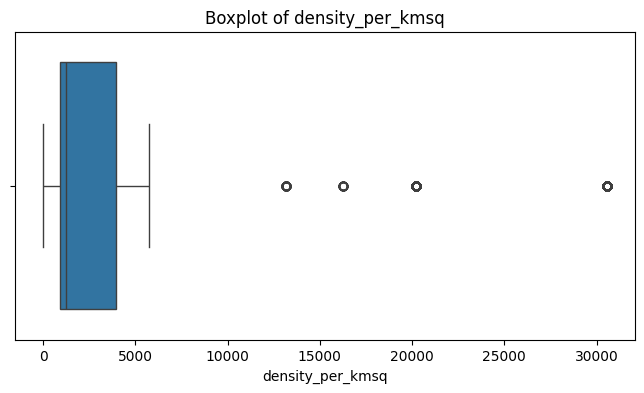

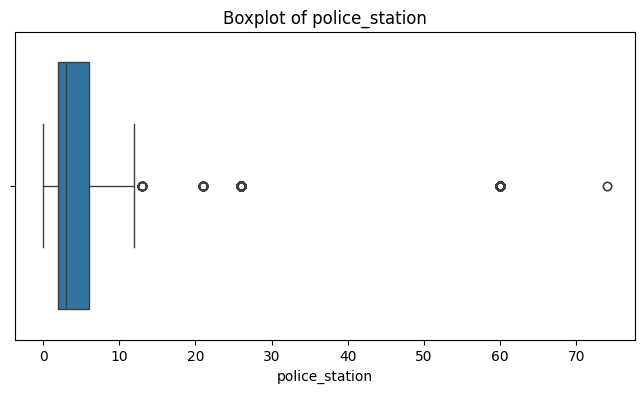

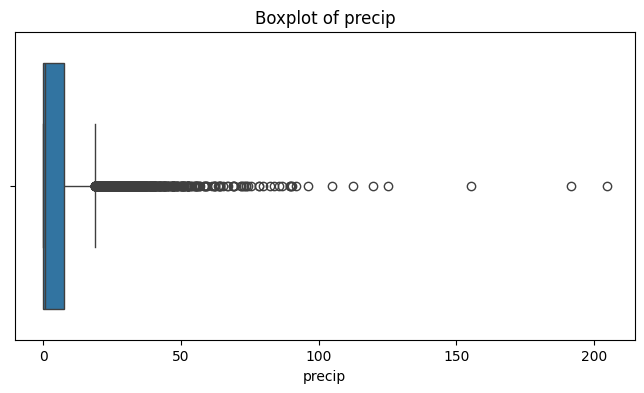

In [18]:
#biar gk kbnyakan ambil 3 kolom utama sj
cols_visual = ['density_per_kmsq', 'police_station', 'precip']

for col in cols_visual:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [19]:
for col in num_cols:
    if col != 'weekend' and 'Unnamed' not in col:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
        df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

outlier_summary = {}
for col in num_cols:
    if col != 'weekend' and 'Unnamed' not in col:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        outlier_summary[col] = len(outliers)
for k, v in outlier_summary.items():
    if v > 0:
        print(f"Masih ada {v} outlier di {k}")

if sum(outlier_summary.values()) == 0:
    print("tdiak ada ooutlier")

tdiak ada ooutlier


In [20]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()


Duplicate rows: 0


C:\Users\sudia\AppData\Local\Temp\ipykernel_29268\427545303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='incident_division', data=df, palette='viridis',
C:\Users\sudia\AppData\Local\Temp\ipykernel_29268\427545303.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='part_of_the_day', data=df, palette='magma',


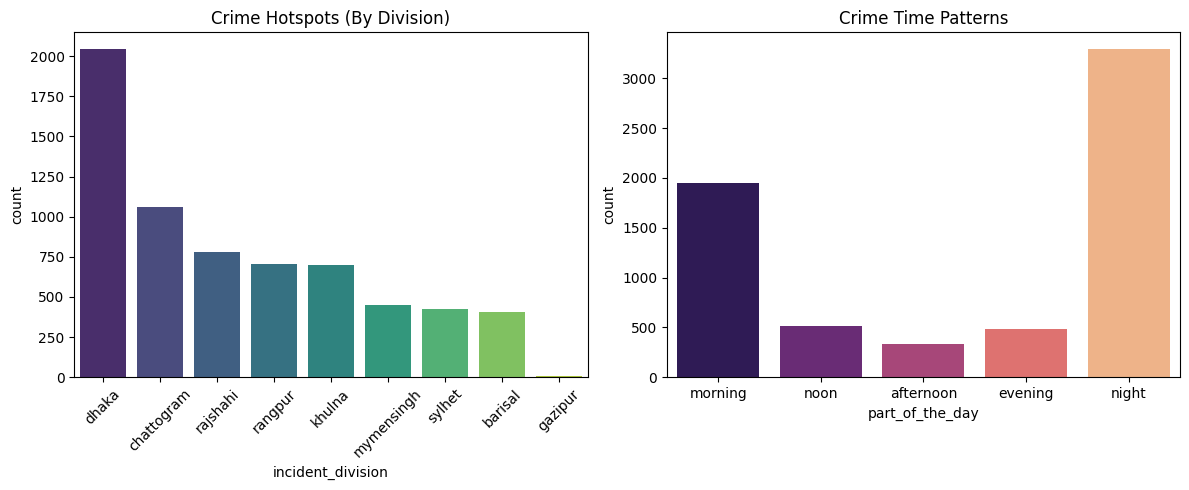

In [21]:
plt.figure(figsize=(12, 5))

# grafik 1:  Kejahatan per Wilayah
plt.subplot(1, 2, 1)
sns.countplot(x='incident_division', data=df, palette='viridis', 
              order=df['incident_division'].value_counts().index)
plt.title('Crime Hotspots (By Division)')
plt.xticks(rotation=45)

# grafik 2 :  Waktu Kejadian
plt.subplot(1, 2, 2)
sns.countplot(x='part_of_the_day', data=df, palette='magma', 
              order=['morning', 'noon', 'afternoon', 'evening', 'night'])
plt.title('Crime Time Patterns')

plt.tight_layout()
plt.show()

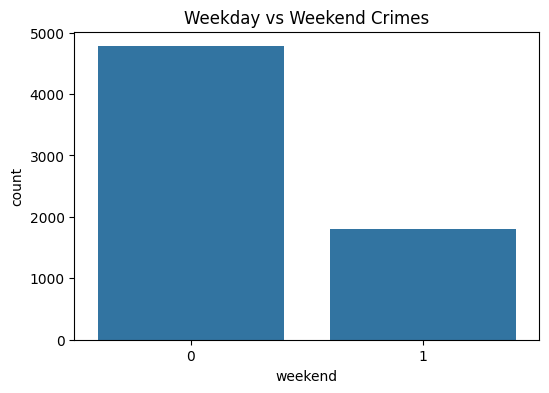

In [22]:
plt.figure(figsize=(6,4))
sns.countplot(x="weekend", data=df)
plt.title("Weekday vs Weekend Crimes")
plt.show()


Tabel Angka Korelasi:
                        total_population  density_per_kmsq  police_station  \
total_population                    1.00              0.92            0.83   
density_per_kmsq                    0.92              1.00            0.85   
police_station                      0.83              0.85            1.00   
literacy_rate                       0.72              0.75            0.69   
precip                             -0.04             -0.03           -0.02   
average_household_size              0.53              0.61            0.59   

                        literacy_rate  precip  average_household_size  
total_population                 0.72   -0.04                    0.53  
density_per_kmsq                 0.75   -0.03                    0.61  
police_station                   0.69   -0.02                    0.59  
literacy_rate                    1.00   -0.04                    0.45  
precip                          -0.04    1.00                   -0.00  

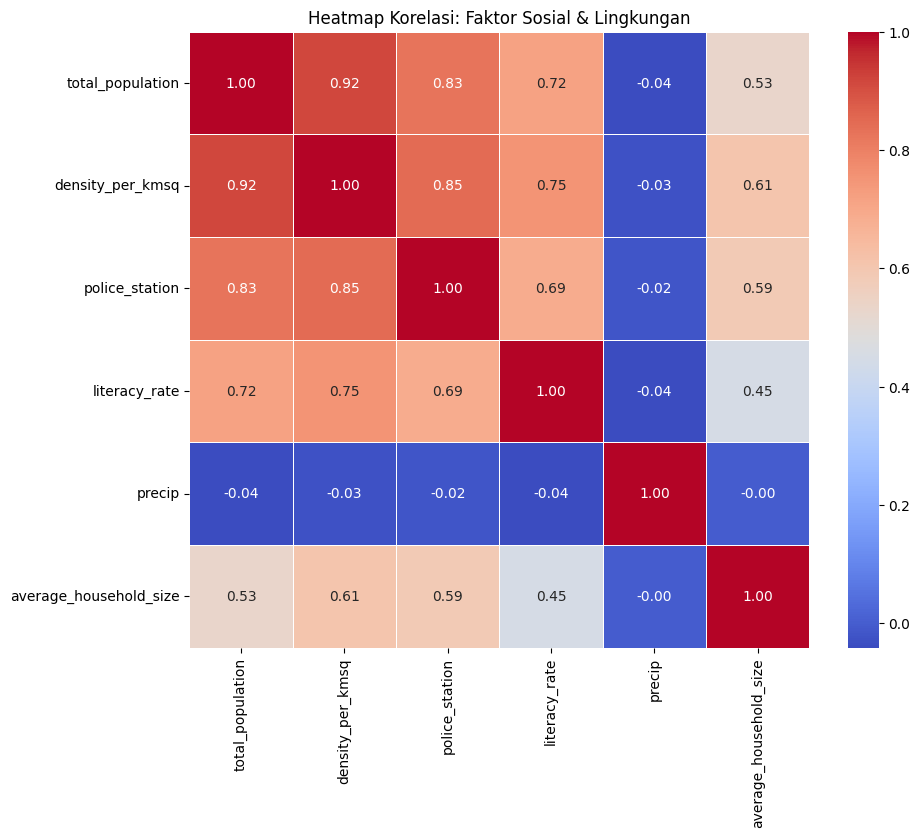

In [23]:
#plih grafik penting sj biar tdk pusing
cols_to_check = ['total_population', 'density_per_kmsq', 'police_station', 
                 'literacy_rate', 'precip', 'average_household_size']

corr_matrix = df[cols_to_check].corr()

print("Tabel Angka Korelasi:")
print(corr_matrix)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Heatmap Korelasi: Faktor Sosial & Lingkungan')
plt.show()

A. Conduct an Exploratory Data Analysis (EDA) on the dataset. 
Highlight the main insights and any irregularities you find, and address those anomalies appropriately! 

1. Data Quality & Anomaly Management: During the initial data audit process, several inconsistencies were identified that required special handling to maintain statistical validity. The main issues included inconsistent text formatting in the incident_division column (variations of "Dhaka", "dhaka", "dHaka",dkk), which was normalized to lowercase, resulting in nine unique regional entities. Furthermore, significant logic errors, such as negative values ​​for the number of police stations and an unusually extreme value (e+56) for population density, were eliminated. A total of 1,491 missing values ​​were imputed using the Median for numeric data and the Mode for categorical data. An IQR-based capping method was used to smooth out outliers in the numeric data distribution to ensure unbiased subsequent analysis.

2. Key Insights & Crime Patterns: Based on data visualization, the Dhaka region was identified as a major crime hotspot with a total of 2,046 incidents, a figure significantly exceeding other divisions and in line with its status as a densely populated center. Temporally, nighttime was the most critical time, with a total of 3,296 incidents, dominated by murder. This finding indicates the urgency of allocating more intensive security patrols during these hours.

3. Correlation Analysis of Socio-Infrastructure Factors: The correlation matrix analysis shows a very strong linear relationship between demographic and infrastructure variables. There is a significant positive correlation (0.85) between population density (density_per_kmsq) and the number of police stations (police_station), and a correlation of 0.92 between total population and area density. This confirms that the current distribution of police stations effectively follows population concentration—the denser an area, the more security facilities are available. Interestingly, environmental factors such as precipitation show a correlation close to zero (-0.04), indicating that weather conditions have no significant influence on crime frequency.

5. Crime Patterns: The Dhaka region has been identified as a high-crime hotspot, with incidents peaking at night and dominated by murders. This indicates the need for increased security in the capital during these critical times.
Infrastructure & Population Relationship: There is a very strong positive correlation (0.85) between population density and the number of police stations. This data confirms that the distribution of government security facilities is effective and proportional: the more densely populated an area, the more police stations are available.

B. Train K-Means and tune it based on a minimum of two metrics. Afterward, visualize the final clusters! 

In [24]:
df_cluster = df.drop(columns=['Unnamed: 0', 'crime'], errors='ignore') 
le = LabelEncoder()
for col in df_cluster.select_dtypes(include=['object']).columns:
    df_cluster[col] = le.fit_transform(df_cluster[col])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster)

In [25]:
inertia = []
sil_scores = []
K_range = range(2, 7) 

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)
    sil = silhouette_score(X_scaled, km.labels_)
    sil_scores.append(sil)
    print(f"K={k} = Silhouette Score: {sil:.4f}")

K=2 = Silhouette Score: 0.3593
K=3 = Silhouette Score: 0.2710
K=4 = Silhouette Score: 0.1637
K=5 = Silhouette Score: 0.1736
K=6 = Silhouette Score: 0.1792


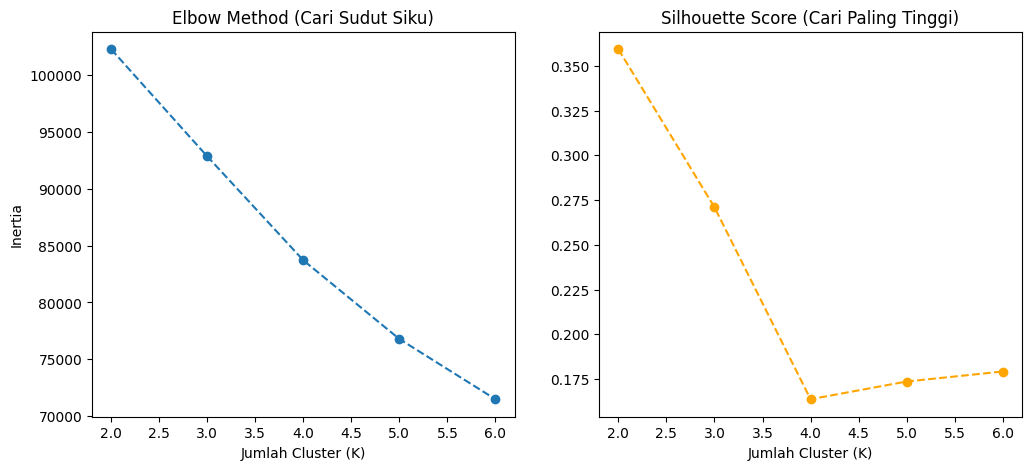

In [26]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(K_range, inertia, marker='o', linestyle='--')
plt.title('Elbow Method (Cari Sudut Siku)')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')

plt.subplot(1, 2, 2)
plt.plot(K_range, sil_scores, marker='o', color='orange', linestyle='--')
plt.title('Silhouette Score (Cari Paling Tinggi)')
plt.xlabel('Jumlah Cluster (K)')
plt.show()

In [27]:
best_k = K_range[np.argmax(sil_scores)] 
print(f"\n K Terbaik yang dipilih: {best_k}")

#train model final
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
labels = kmeans_final.fit_predict(X_scaled)
df['Cluster'] = labels #simpen hasilnny ke data asli




 K Terbaik yang dipilih: 2


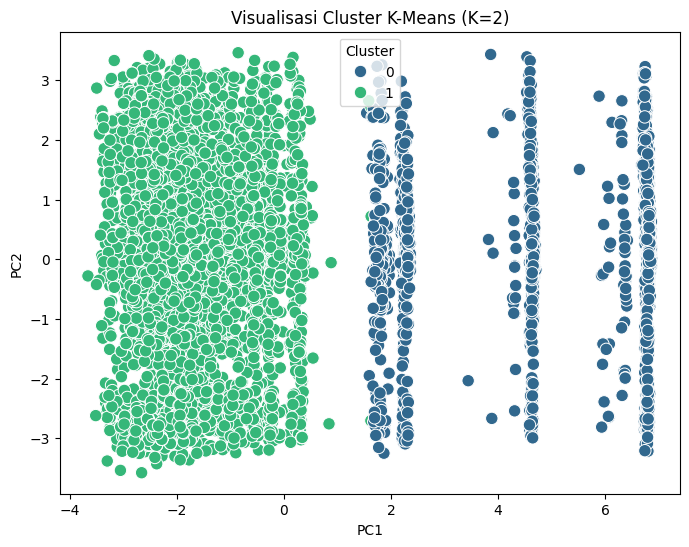

In [28]:
#visualisasi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=df['Cluster'], palette='viridis', s=80)
plt.title(f'Visualisasi Cluster K-Means (K={best_k})')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Cluster')
plt.show()

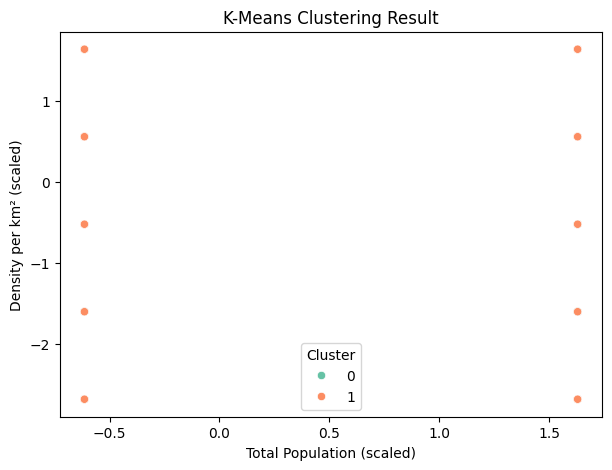

In [29]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    x=X_scaled[:, 3],  
    y=X_scaled[:, 4],  
    hue=df["Cluster"],
    palette="Set2"
)
plt.title("K-Means Clustering Result")
plt.xlabel("Total Population (scaled)")
plt.ylabel("Density per km² (scaled)")
plt.show()


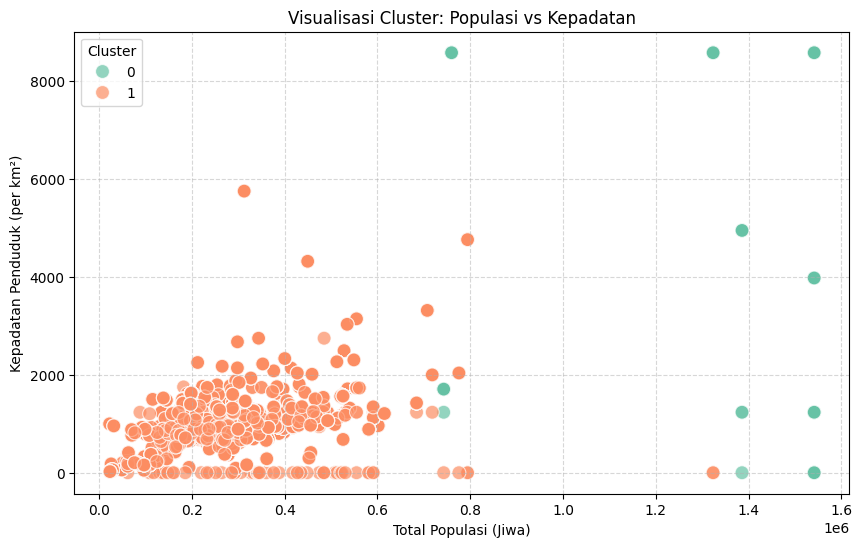

In [30]:
plt.figure(figsize=(10, 6))


sns.scatterplot(
    x=df['total_population'], 
    y=df['density_per_kmsq'], 
    hue=df['Cluster'],
    palette='Set2',
    s=100, 
    alpha=0.7 
)

plt.title("Visualisasi Cluster: Populasi vs Kepadatan")
plt.xlabel("Total Populasi (Jiwa)")
plt.ylabel("Kepadatan Penduduk (per km²)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

C. Profile each cluster to understand its customer characteristics! 

In [31]:
# mean
cols_num = ['total_population', 'police_station', 'density_per_kmsq', 'literacy_rate']
profile_num = df.groupby('Cluster')[cols_num].mean()

# modus
cols_cat = ['incident_division', 'crime', 'part_of_the_day']
profile_cat = df.groupby('Cluster')[cols_cat].agg(lambda x: x.mode()[0])

print("mean\n")
print(profile_num)
print("\nMODUS\n")
print(profile_cat)


print("\n PROFILING ")
for i in range(2):
    pop = profile_num.loc[i, 'total_population']
    lit = profile_num.loc[i, 'literacy_rate']
    div = profile_cat.loc[i, 'incident_division']
    print(f"Cluster {i}:")
    print(f"  - Wilayah Dominan: {div.upper()}")
    print(f"  - Rata-rata Populasi: {pop:,.0f} jiwa")
    print(f"  - Tingkat Literasi: {lit:.1f}%")
    print(f"  - Kategori: {'URBAN (Kota Besar)' if lit > 60 else 'RURAL (Daerah/Desa)'}")
    print()

mean

         total_population  police_station  density_per_kmsq  literacy_rate
Cluster                                                                   
0              1455399.46           10.32           7360.29          70.06
1               333992.60            2.78           1220.52          50.69

MODUS

        incident_division      crime part_of_the_day
Cluster                                             
0                   dhaka  bodyfound           night
1                rajshahi     murder           night

 PROFILING 
Cluster 0:
  - Wilayah Dominan: DHAKA
  - Rata-rata Populasi: 1,455,399 jiwa
  - Tingkat Literasi: 70.1%
  - Kategori: URBAN (Kota Besar)

Cluster 1:
  - Wilayah Dominan: RAJSHAHI
  - Rata-rata Populasi: 333,993 jiwa
  - Tingkat Literasi: 50.7%
  - Kategori: RURAL (Daerah/Desa)



C:\Users\sudia\AppData\Local\Temp\ipykernel_29268\3644474573.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y=col, data=df, palette='viridis')
C:\Users\sudia\AppData\Local\Temp\ipykernel_29268\3644474573.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y=col, data=df, palette='viridis')
C:\Users\sudia\AppData\Local\Temp\ipykernel_29268\3644474573.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y=col, data=df, palette='viridis')
C:\Users\sudia\AppData\Local\Temp\ipykernel_29268\3644474573.

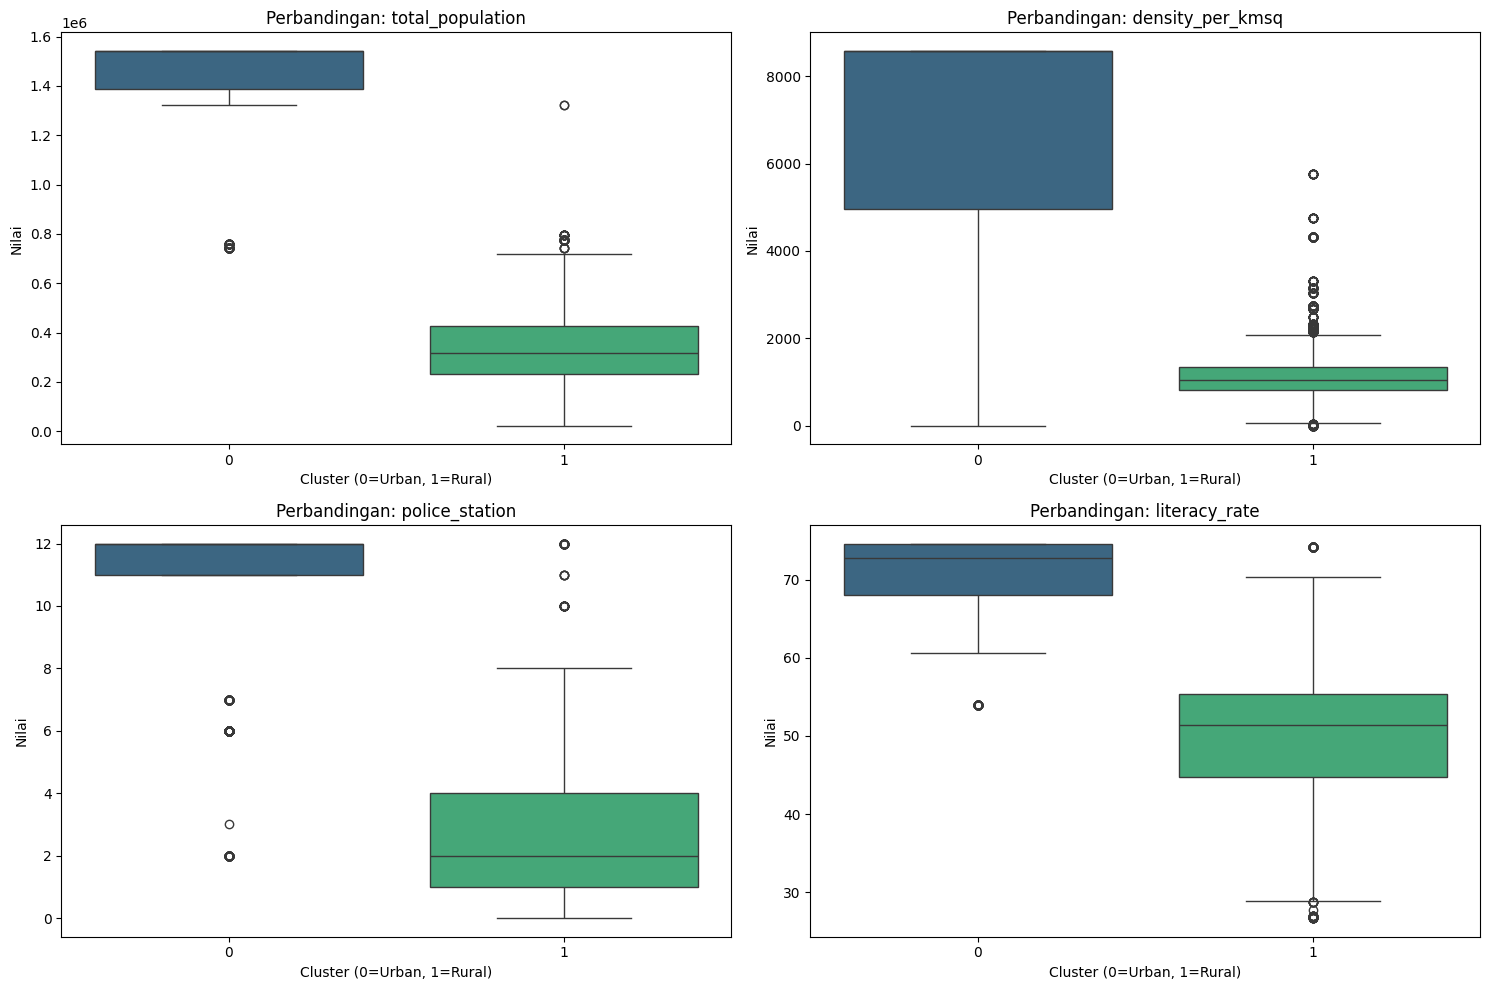

In [32]:
features = ['total_population', 'density_per_kmsq', 'police_station', 'literacy_rate']


plt.figure(figsize=(15, 10))

for i, col in enumerate(features):
    plt.subplot(2, 2, i+1)
    

    sns.boxplot(x='Cluster', y=col, data=df, palette='viridis')

    plt.title(f'Perbandingan: {col}', fontsize=12)
    plt.xlabel('Cluster (0=Urban, 1=Rural)')
    plt.ylabel('Nilai')

plt.tight_layout()
plt.show()

Conclusion & Cluster Profiling Analysis

The K-Means clustering analysis successfully segmented the regions into two distinct profiles based on demographic and security characteristics: Urban Metropolitan (Cluster 0) and Rural Developing (Cluster 1). Cluster 0, predominantly represented by Dhaka, is characterized by high population density (averaging 1.45 million inhabitants) and advanced social indicators, including a significantly higher literacy rate of 70.1%. This cluster benefits from robust security infrastructure with an average of 10.3 police stations per area, though the prevalence of "Bodyfound" cases suggests challenges related to urban anonymity. Conversely, Cluster 1, typified by regions like Rajshahi, represents vulnerable areas with lower population density and a concerning literacy rate of only 50.7%. With limited security resources (averaging just 2.8 police stations), the dominance of "Murder" cases in this cluster highlights a critical need for targeted interventions, focusing on both physical policing infrastructure and social development programs to bridge the gap with metropolitan areas.